In [2]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

import astropy.units as u
import astropy.constants as const
from galpy.orbit import Orbit
from galpy.util import conversion

from galpy.potential import vcirc
from galpy.potential import SCFPotential, scf_compute_coeffs_nbody
from galpy.potential import interpSphericalPotential
from galpy.potential import evaluatePotentials
from galpy.potential import evaluateDensities
from galpy.potential import (PlummerPotential, EinastoPotential,
                             TruncatedNFWPotential, TruncatedHernquistPotential)

In [26]:
data = h5py.File('cutout_188106.hdf5', "r")
type1 = dict(data["PartType1"].attrs)
hdr = dict(data["Header"].attrs)
print(hdr.keys())
print(type('cutout_188106.hdf5'))

dict_keys(['BoxSize', 'CutoutID', 'CutoutRequest', 'CutoutType', 'Git_commit', 'Git_date', 'HubbleParam', 'MassTable', 'NumFilesPerSnapshot', 'NumPart_ThisFile', 'Omega0', 'OmegaBaryon', 'OmegaLambda', 'Redshift', 'SimulationName', 'SnapshotNumber', 'Time', 'UnitLength_in_cm', 'UnitMass_in_g', 'UnitVelocity_in_cm_per_s'])
<class 'str'>


In [ ]:
def potential_plotter(file, plot_potential=True, plot_density=True):
    """
    Builds a spherical potential from the DM particles in 'file' and plots the potential and density

    Parameters:

    file : .hdf5 file
            Data from the  TNG simulation (one halo)

    plot_potential : bool
                     Boolean that determines if the potential should be plotted

    plot_density : bool
                   Boolean that determines if the density should be plotted

    Returns:

    pot : galpy.potential
          The potential constructed from the data in 'file'

    rplot : astropy Quantity
            Radii (kpc) at which the density was evaluated

    rho : astropy Quantity
          Density (Msun/kpc^3) at those radii
    """
    # galpy's unit scales
    ro, vo = 8.0 * u.kpc, 220.0 * u.km / u.s

    # Open file, get particle positions and masses
    with h5py.File(file, "r") as f:
        hdr = dict(f["Header"].attrs)
        pos = f["PartType1/Coordinates"][:]
        m = np.full(len(pos), hdr["MassTable"][1])   # all DM particles have equal mass in TNG

    # Get hubble param and divide by it, convention in TNG
    h = hdr.get("HubbleParam", 1.0)
    L_unit = hdr.get("UnitLength_in_cm", 3.085678e21) * u.cm / h
    M_unit = hdr.get("UnitMass_in_g", 1.989e43) * u.g / h

    # Convert data to more conventional units
    pos = pos * L_unit.to(u.kpc)
    m = m * M_unit.to(u.Msun)

    # Calculate the center of all particles
    center = np.average(pos.value, axis=0, weights=m.value) * u.kpc
    # Calculate all radii w.r.t. center and sort them in increasing r
    r = np.linalg.norm((pos - center).value, axis=1) * u.kpc
    order = np.argsort(r)
    # The mass is the total enclosed mass
    r, M = r[order], np.cumsum(m[order])

    # Make a grid of radii, interpolate between radii in r and assign a mass to each gridpoint.
    # Only start at the 100th particle, starting from the 0th particle includes too much noise
    rgrid_phys = np.geomspace(r[100], r[-1], 200)
    Mgrid_phys = np.interp(rgrid_phys, r, M)

    # Radial force grid in physical units, with G from astropy: F = -G M / r^2  [(km/s)^2 / kpc]
    Fgrid_phys = (-const.G * Mgrid_phys / rgrid_phys**2).to(u.km**2 / u.s**2 / u.kpc)

    # Express rgrid and Fgrid in galpy's unit scales
    rgrid = (rgrid_phys / ro).decompose().value
    Fgrid = (Fgrid_phys / (vo**2 / ro)).decompose().value

    pot = interpSphericalPotential(
        rforce=lambda x: np.interp(x, rgrid, Fgrid),
        rgrid=rgrid, ro=ro.to_value(u.kpc), vo=vo.to_value(u.km / u.s))

    # Get the potentia at the grid points
    Phi = evaluatePotentials(pot, rgrid_phys, 0. * u.kpc, quantity=True)
    Phi = Phi.to(u.km**2 / u.s**2)
    # Shift so the outer edge matches a point mass, Phi = -G M_tot / r (zero at infinity)
    Phi = Phi - Phi[-1] + (-const.G * Mgrid_phys[-1] / rgrid_phys[-1]).to(u.km**2 / u.s**2)

    # Get the density at the grid points
    rho = evaluateDensities(pot, rgrid_phys, 0. * u.kpc, quantity=True)
    rho = rho.to(u.Msun / u.kpc**3)

    if plot_potential:
        plt.semilogx(rgrid_phys.value, Phi.value)
        plt.xlabel("r [kpc]")
        plt.ylabel(r"$\Phi$ [(km/s)$^2$]")
        plt.title("Potential")
        plt.show()

    if plot_density:
        plt.loglog(rgrid_phys.value, rho.value)
        plt.xlabel("r [kpc]")
        plt.ylabel(r"$\rho$ [M$_\odot$ kpc$^{-3}$]")
        plt.title("Density profile from the galpy potential")
        plt.show()

    return pot, rgrid_phys, rho, Mgrid_phys

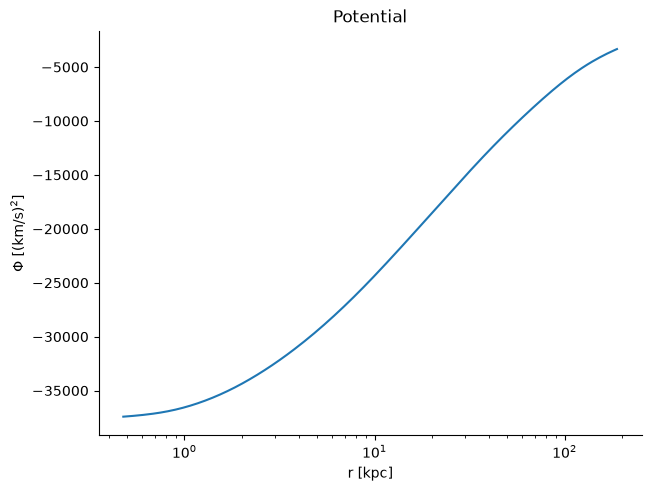

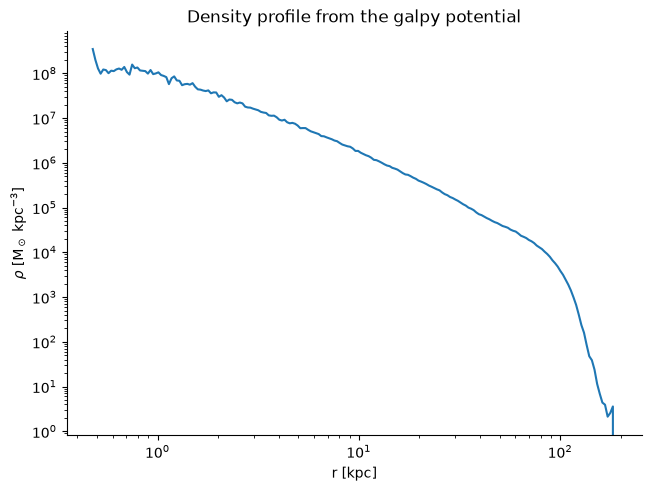

In [28]:
example = potential_plotter('cutout_188106.hdf5', plot_potential=True, plot_density=True)

In [ ]:
def data_fitter(file, plot=True):
    """
    Takes the data from the simulation and fits 4 models: Einasto, Plummer and truncated NFW and
    Hernquist. Returns the fitted parameters and the rms deviation of the fit.

    Parameters:

    file : .hdf5 file
            Data from the  TNG simulation (one halo)

    plot : bool
           Boolean that determines if the results should be plotted

    Returns:

    results_params : dict
            The names of the fitted density models (keys) and the corresponding fitted parameters
            with their corresponding rms values (values)

    results_density : dict
            The names of the fitted density models (keys) and the corresponding model i.e. rho(r)
            (Msun/kpc^3) over the grid (values)

    r : astropy Quantity
            Radii (kpc) at which the density was evaluated

    """

    # Extract potential and density from the data
    pot, r, rho, m = potential_plotter(file, plot_potential=False, plot_density=False)

    # galpy's unit scales as plain numbers (kpc, km/s), only used to construct the fit models
    ro, vo = 8.0, 220.0

    # units to express results in, dimensionless unit needed for Einasto
    one = u.dimensionless_unscaled
    rho_unit = u.Msun / u.kpc**3

    # Density models: galpy potentials evaluated through their analytic density
    def plummer(r, amp, b):
        p = PlummerPotential(amp=amp, b=b, ro=ro, vo=vo)
        return evaluateDensities(p, r, 0. * u.kpc, quantity=True)

    def einasto(r, amp, rm2, n):
        p = EinastoPotential(amp=amp, rm2=rm2, n=float(n), ro=ro, vo=vo)
        return evaluateDensities(p, r, 0. * u.kpc, quantity=True)

    def nfw_trunc(r, amp, a, rc):
        p = TruncatedNFWPotential(amp=amp, a=a, rc=rc, ro=ro, vo=vo)
        return evaluateDensities(p, r, 0. * u.kpc, quantity=True)

    def hernquist_trunc(r, amp, a, rc):
        p = TruncatedHernquistPotential(amp=amp, a=a, rc=rc, ro=ro, vo=vo)
        return evaluateDensities(p, r, 0. * u.kpc, quantity=True)

    # Drop non-positive densities (the derivative of the interpolated force can be noisy),
    # since we fit in log space
    good = rho > 0 * rho_unit
    r_fit, rho_fit = r[good], rho[good]

    # A function to perform a single fit, note that scipy doesn't take astropy units so the
    # variables of this function shouldn't have units (andd won't have them if scipy uses the
    # function)
    def fit(model, p0, units):
        """
        Fit in log space. This fits log(rho) as a function of r
        Parameters are log10 of their value in 'units', so they stay positive.
        """
        # This is the functin that's fitted, takes a model and takes log() of it.
        def log_model(r_val, *logp):
            # Reattach units to the parameters, what scipy puts into this function won't have units
            params = [10**lp * un for lp, un in zip(logp, units)]
            # Evaluate the log(model), the galpy model *does* need units so they're reattached
            return np.log10(model(r_val * u.kpc, *params).to_value(rho_unit))

        # Apply the scipy curve fit on the function that doesn't need units itself, returns
        # (fitted parameters, covariance). Note that .to_value is used because scipy doesn't take
        # units!
        popt, cov = curve_fit(log_model,
                            r_fit.to_value(u.kpc),
                            np.log10(rho_fit.to_value(rho_unit)),
                            p0=np.log10([p.to_value(un) for p, un in zip(p0, units)]),
                            maxfev=10000)
        # Return everything, undo the logarithm, reattach units
        return [10**p * un for p, un in zip(popt, units)]

    # Starting guesses from the data: scale radius a0 and density rho0 at the middle of the grid
    a0 = r_fit[len(r_fit) // 2]
    rho0 = rho_fit[len(r_fit) // 2]
    rc0 = r_fit[-1] / 2

    models = {
        # Plummer: rho(b) = 3 amp / (4 pi b^3) * 2^(-5/2)
        "Plummer":             (plummer,         [rho0 * 4 * np.pi * a0**3 / 3 * 2**2.5, a0],  [u.Msun, u.kpc]),
        # Einasto: rho(rm2) = amp, so amp ~ rho0 at rm2 ~ a0
        "Einasto":             (einasto,         [rho0, a0, 5 * one],                       [rho_unit, u.kpc, one]),
        # NFW: rho(a) = amp / (4 pi a^3) / 4
        "Truncated NFW":       (nfw_trunc,       [4 * rho0 * 4 * np.pi * a0**3, a0, rc0],   [u.Msun, u.kpc, u.kpc]),
        # Hernquist: rho(a) = amp / (4 pi a^3) / 8
        "Truncated Hernquist": (hernquist_trunc, [8 * rho0 * 4 * np.pi * a0**3, a0, rc0],   [u.Msun, u.kpc, u.kpc]),
    }

    # Fit every model first, keep the results
    results_density = {}
    results_params = {}
    for name, (model, p0, units) in models.items():
        params = fit(model, p0, units)
        rho_model = model(r, *params).to_value(rho_unit)

        # rms residual in log10 space, over the points used in the fit
        resid = (np.log10(model(r_fit, *params).to_value(rho_unit))
                 - np.log10(rho_fit.to_value(rho_unit)))
        rms = np.sqrt(np.mean(resid**2))

        results_params[name] = (params, rms)
        results_density[name] = (rho_model, rms)

    if plot:
        # Layout: five panels in one row (overlay first, then each fit), all sharing the same x and y axes
        fig, axes = plt.subplots(1, 5, figsize=(50, 10), sharex=True, sharey=True)

        # Same axis limits for every panel, set from the data
        ymin = rho_fit.to_value(rho_unit).min() / 3
        ymax = rho_fit.to_value(rho_unit).max() * 3

        # 1) All fits overlaid
        ax = axes[0]
        ax.loglog(r.value, rho.value, "k", lw=2, label="galpy density")
        for name, (rho_model, rms) in results_density.items():
            ax.loglog(r.value, rho_model, "--", label=name)
        ax.set(xlabel="r [kpc]", ylabel=r"$\rho$ [M$_\odot$ kpc$^{-3}$]", title="All fits")
        ax.legend()

        # 2-5) Each fit on its own
        for ax, (name, (rho_model, rms)) in zip(axes[1:], results_density.items()):
            ax.loglog(r.value, rho.value, "k", lw=2, label="galpy density")
            ax.loglog(r.value, rho_model, "r--", label=name)
            ax.set(xlabel="r [kpc]", title=f"{name} (rms = {rms:.3f})")
            ax.legend()

        axes[0].set_ylim(ymin, ymax)   # sharey propagates this to all panels

        plt.tight_layout()
        plt.show()

    return (results_params, results_density, r)

/tmp/ipykernel_6455/233387758.py:143: UserWarning: The figure layout has changed to tight
  plt.tight_layout()



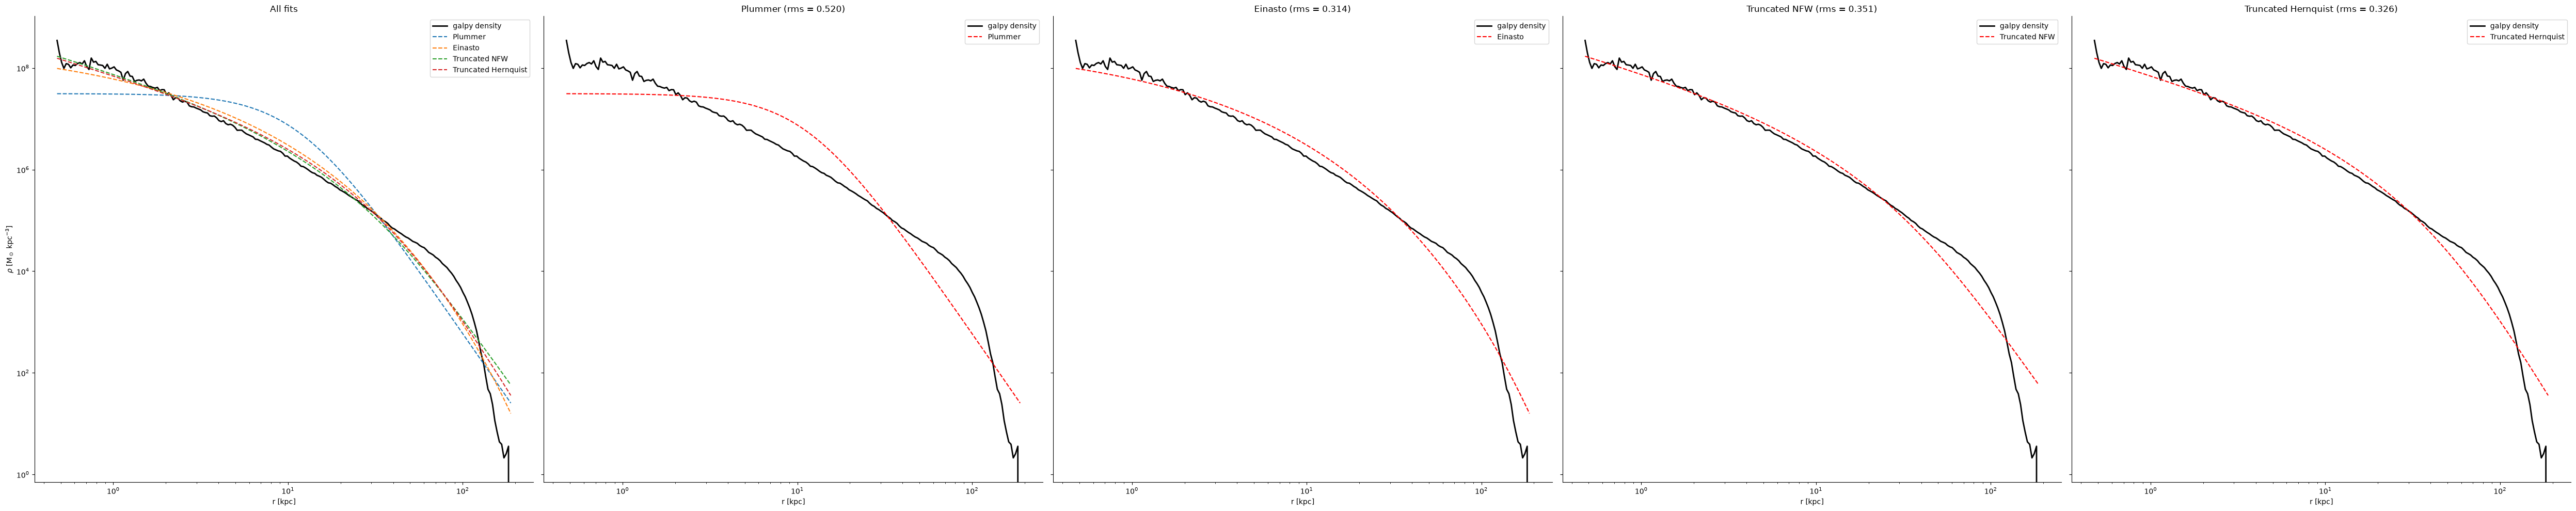

In [30]:
params, density, r = data_fitter('cutout_188106.hdf5')

In [ ]:
def build_Einasto(file):
    """
    Takes the data from the simulation and constructs the Einasto model with the fitted parameters
    supplied by "data_fitter"

    Parameters:

    file : .hdf5 file
            Data from the  TNG simulation (one halo)

    Returns:

    pot_einasto : galpy.potential
            The galpy Einasto potential made with the fitted parameters returned by "data_fitter"

    rho_einasto : astropy Quantity
            The Einasto density profile (Msun/kpc^3) corresponding to the constructed Einasto
            potential

    r : astropy Quantity
            Radii (kpc) at which the density was evaluated

    """
    params, densities, r = data_fitter(file, plot=False)

    # galpy's unit scales (kpc, km/s)
    ro, vo = 8.0, 220.0

    # Fitted Einasto parameters: amp (Msun/kpc^3), rm2 (kpc), n (dimensionless)
    (amp_e, rm2_e, n_e), rms = params["Einasto"]

    # Build the galpy potential from the fitted parameters
    pot_einasto = EinastoPotential(amp=amp_e, rm2=rm2_e, n=n_e.to_value(u.dimensionless_unscaled),
                                ro=ro, vo=vo)
    # Calculate the density from the potential
    rho_einasto = evaluateDensities(pot_einasto, r, 0. * u.kpc, quantity=True).to(u.Msun / u.kpc**3)

    return (pot_einasto, rho_einasto, r)

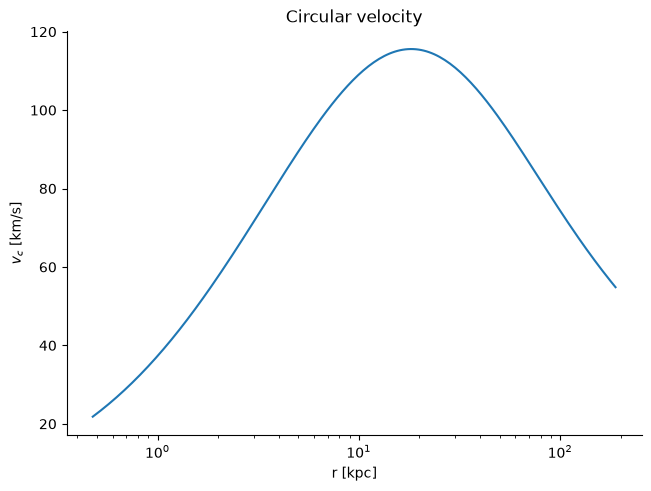

In [32]:
def circular_velocity(pot, r, plot=True):
    """
    Computes the circular velocity v_c(r) = sqrt(r |F_r|) = sqrt(G M(<r) / r) of a spherical galpy
    potential and optionally plots it as a function of r.

    Parameters:

    pot : galpy.potential
          The spherical potential: pot_einasto from build_Einasto

    r : astropy Quantity
        Radii (kpc) at which to evaluate v_c: the grid returned by build_Einasto

    plot : bool
           Whether to plot v_c as a function of r

    Returns:

    vc : astropy Quantity
         The circular velocity (km/s) at the radii in 'r'

    """
    # Get the circular velocity using galpy
    vc = vcirc(pot, r).to(u.km / u.s)

    # Standard plotting, vc as a function of radius
    if plot:
        plt.semilogx(r.to_value(u.kpc), vc.value)
        plt.xlabel("r [kpc]")
        plt.ylabel(r"$v_c$ [km/s]")
        plt.title("Circular velocity")
        plt.show()

    return vc

pot_einasto, rho_einasto, r = build_Einasto("cutout_188106.hdf5")
vc = circular_velocity(pot_einasto, r)

/tmp/ipykernel_6455/2163300368.py:77: UserWarning: The figure layout has changed to tight
  plt.tight_layout()



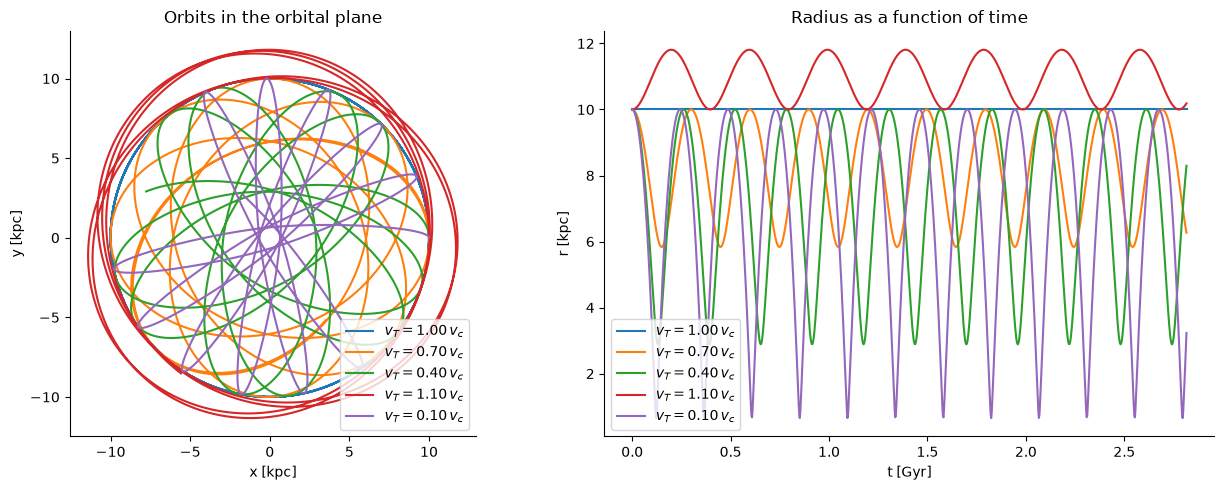

In [33]:
def integrate_orbits(pot, r0, f_vc, n_orbits=5, n_steps=1000,
                     ro=8.0, vo=220.0, plot=True):
    """
    Integrates orbits in a spherical galpy potential and optionally plots them. Every orbit starts
    at radius r0 in the z = 0 plane with a purely tangential velocity f * v_c(r0).

    Parameters:

    pot : galpy.potential
          The spherical potential, e.g. pot_einasto from build_Einasto

    r0 : astropy Quantity
         Starting radius (kpc), should be inside the range covered by the particles.

    f_vc : sequence of float
           Tangential velocity of each orbit as a fraction of the circular velocity at r0.
           1.0 is a circular orbit. Smaller values give eccentric orbits for which r0 is the
           apocenter.

    n_orbits : float
               Integration time in units of the circular orbital period at r0

    n_steps : int
              Number of time steps

    ro, vo : float
             galpy's unit scales (kpc, km/s), must be the same as used for the potential

    plot : bool
           Whether to plot the orbits

    Returns:

    orbits : list of galpy.orbit.Orbit
             The integrated orbits, one for each value in f_vc

    ts : list of astropy Quantity
         The times (Gyr) at which each orbit was integrated

    """
    # Get the velocity at the starting point r0
    vc0 = vcirc(pot, r0).to(u.km / u.s)

    # Integrate for n_orbits circular periods at r0, standard formula for period in spherically
    # symmetric potential
    T = n_orbits * (2 * np.pi * r0 / vc0).to(u.Gyr)
    ts = np.linspace(0, T.to_value(), n_steps) * u.Gyr

    orbits = []
    for f in f_vc:
        # [R, vR, vT, z, vz, phi]: purely tangential velocity, in the z = 0 plane. galpy expects
        # the coordinates to be given in this order
        o = Orbit([r0, 0. * u.km / u.s, f * vc0, 0. * u.kpc, 0. * u.km / u.s, 0. * u.rad],
                  ro=ro, vo=vo)
        # Integrate orbit and append to the collection of orbits
        o.integrate(ts, pot)
        orbits.append(o)

    # Standard plotting, note that you need "normal" values for matplotlib to do its thing. We make
    # sure everything is in kpc and Gyr
    if plot:
        fig, ax = plt.subplots(1, 2, figsize=(13, 5))

        for f, o in zip(f_vc, orbits):
            x = o.x(ts).to_value(u.kpc)
            y = o.y(ts).to_value(u.kpc)
            r = o.r(ts).to_value(u.kpc)

            ax[0].plot(x, y, label=rf"$v_T = {f:.2f}\,v_c$")
            ax[1].plot(ts.to_value(u.Gyr), r, label=rf"$v_T = {f:.2f}\,v_c$")

        ax[0].set(xlabel="x [kpc]", ylabel="y [kpc]", title="Orbits in the orbital plane", aspect="equal")
        ax[0].legend()
        ax[1].set(xlabel="t [Gyr]", ylabel="r [kpc]", title="Radius as a function of time")
        ax[1].legend()

        plt.tight_layout()
        plt.show()

    return orbits, [ts] * len(orbits)

pot_einasto, rho_einasto, r = build_Einasto("cutout_188106.hdf5")
orbits, ts = integrate_orbits(pot_einasto, r0=10 * u.kpc, f_vc=(1.0, 0.7, 0.4, 1.1, 0.1))

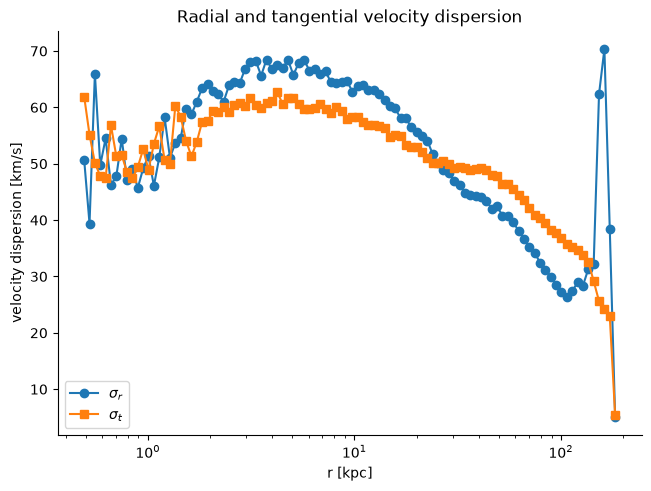

In [34]:
def velocity_dispersions(file, n_bins=20, plot=True, return_counts=False):
    """
    Measures the radial and tangential velocity dispersion of the DM particles as a function of
    radius, in logarithmic spherical shells around the center of the halo.

    The tangential dispersion is defined per component: sigma_t^2 = (sigma_theta^2 + sigma_phi^2) / 2,
    so that an isotropic halo has sigma_t = sigma_r.

    Parameters:

    file : .hdf5 file
           Data from the TNG simulation (one halo)

    n_bins : int
             Number of logarithmic radial shells

    plot : bool
           Whether to plot the dispersions as a function of r

    Returns:

    r_mid : astropy Quantity
            Geometric center of each shell (kpc)

    sigma_r : astropy Quantity
              Radial velocity dispersion (km/s) in each shell

    sigma_t : astropy Quantity
              Tangential velocity dispersion (km/s) per component, in each shell

    """
    with h5py.File(file, "r") as f:
        hdr = dict(f["Header"].attrs)
        pos = f["PartType1/Coordinates"][:]
        vel = f["PartType1/Velocities"][:]

    # Same unit conventions as before. TNG velocities are stored as v * sqrt(a), with a the scale
    # factor (a = 1 at z = 0)
    h = hdr.get("HubbleParam", 1.0)
    a = hdr.get("Time", 1.0)
    L_unit = hdr.get("UnitLength_in_cm", 3.085678e21) * u.cm / h
    v_unit = hdr.get("UnitVelocity_in_cm_per_s", 1e5) * u.cm / u.s

    pos = pos * L_unit.to(u.kpc)
    vel = vel * np.sqrt(a) * v_unit.to(u.km / u.s)

    # Positions relative to the center, velocities relative to the bulk velocity of the halo
    # (all particles have the same mass)
    x = (pos - pos.mean(axis=0)).value
    v = (vel - vel.mean(axis=0)).value

    r = np.linalg.norm(x, axis=1)
    theta = np.arccos(x[:, 2] / r)
    phi = np.arctan2(x[:, 1], x[:, 0])

    # Spherical unit vectors at the position of each particle
    e_r = x / r[:, None]
    e_th = np.column_stack([np.cos(theta) * np.cos(phi), np.cos(theta) * np.sin(phi), -np.sin(theta)])
    e_ph = np.column_stack([-np.sin(phi), np.cos(phi), np.zeros_like(phi)])

    # Velocity components in spherical coordinates
    v_r = np.sum(v * e_r, axis=1)
    v_th = np.sum(v * e_th, axis=1)
    v_ph = np.sum(v * e_ph, axis=1)

    # Logarithmic shells, from the 100th particle (as before, inside that it is noise) to the outermost
    edges = np.geomspace(np.sort(r)[100], r.max(), n_bins + 1)
    shell = np.digitize(r, edges) - 1

    counts = np.zeros(n_bins, dtype=int)
    sigma_r = np.full(n_bins, np.nan)
    sigma_t = np.full(n_bins, np.nan)
    for i in range(n_bins):
        sel = shell == i
        counts[i] = sel.sum()
        if sel.sum() < 2:
            continue
        # The standard deviation within a shell removes any mean streaming motion of the shell
        sigma_r[i] = v_r[sel].std()
        sigma_t[i] = np.sqrt((v_th[sel].var() + v_ph[sel].var()) / 2)

    r_mid = np.sqrt(edges[1:] * edges[:-1]) * u.kpc
    sigma_r = sigma_r * u.km / u.s
    sigma_t = sigma_t * u.km / u.s

    if plot:
        plt.semilogx(r_mid.to_value(u.kpc), sigma_r.to_value(u.km / u.s), "o-", label=r"$\sigma_r$")
        plt.semilogx(r_mid.to_value(u.kpc), sigma_t.to_value(u.km / u.s), "s-", label=r"$\sigma_t$")
        plt.xlabel("r [kpc]")
        plt.ylabel("velocity dispersion [km/s]")
        plt.title("Radial and tangential velocity dispersion")
        plt.legend()
        plt.show()

    if return_counts:
        return r_mid, sigma_r, sigma_t, edges * u.kpc, counts
    return r_mid, sigma_r, sigma_t

r_mid, sigma_r, sigma_t = velocity_dispersions("cutout_188106.hdf5", n_bins=100)

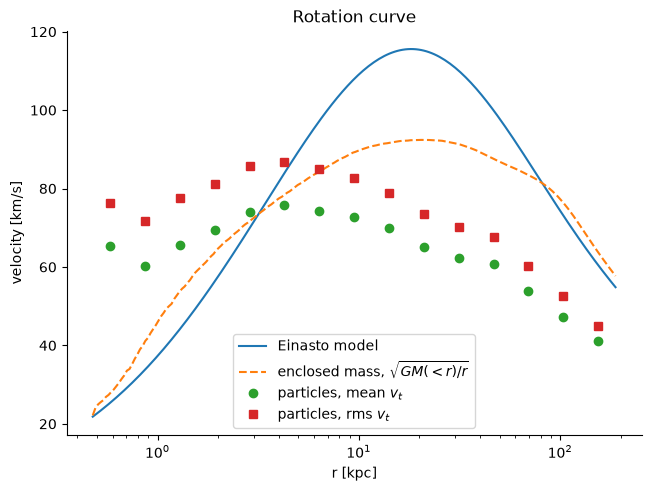

In [35]:
import h5py
import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt
from astropy.constants import G

def tangential_velocity(file, n_bins=15):
    """
    Measures the full tangential velocity v_t of the DM particles as a function of radius, in
    logarithmic spherical shells. v_t is the speed perpendicular to the radial direction,
    v_t = sqrt(v_theta^2 + v_phi^2) = sqrt(|v|^2 - v_r^2).

    Parameters:

    file : .hdf5 file
           Data from the TNG simulation (one halo)

    n_bins : int
             Number of logarithmic radial shells

    Returns:

    r_mid : astropy Quantity
            Geometric center of each shell (kpc)

    vt_mean : astropy Quantity
              Mean tangential speed v_t in each shell (km/s)

    vt_rms : astropy Quantity
             Root-mean-square tangential speed in each shell (km/s), sqrt(<v_t^2>)

    """
    with h5py.File(file, "r") as f:
        hdr = dict(f["Header"].attrs)
        pos = f["PartType1/Coordinates"][:]
        vel = f["PartType1/Velocities"][:]

    # Same unit conventions as before. TNG velocities are stored as v * sqrt(a), with a the scale
    # factor (a = 1 at z = 0)
    h = hdr.get("HubbleParam", 1.0)
    a = hdr.get("Time", 1.0)
    L_unit = hdr.get("UnitLength_in_cm", 3.085678e21) * u.cm / h
    v_unit = hdr.get("UnitVelocity_in_cm_per_s", 1e5) * u.cm / u.s

    pos = pos * L_unit.to(u.kpc)
    vel = vel * np.sqrt(a) * v_unit.to(u.km / u.s)

    # Positions relative to the center, velocities relative to the bulk velocity of the halo
    # (all particles have the same mass)
    x = (pos - pos.mean(axis=0)).value
    v = (vel - vel.mean(axis=0)).value
    r = np.linalg.norm(x, axis=1)

    # Radial velocity: the projection of the velocity onto the radial direction
    e_r = x / r[:, None]
    v_r = np.sum(v * e_r, axis=1)

    # What remains of the speed after removing the radial part is perpendicular to the radius
    # (the maximum guards against tiny negative values from rounding errors)
    v_t = np.sqrt(np.maximum(np.sum(v**2, axis=1) - v_r**2, 0.))

    # Logarithmic shells, from the 100th particle (as before, inside that it is noise) to the outermost
    edges = np.geomspace(np.sort(r)[100], r.max(), n_bins + 1)
    shell = np.digitize(r, edges) - 1

    vt_mean = np.full(n_bins, np.nan)
    vt_rms = np.full(n_bins, np.nan)
    for i in range(n_bins):
        sel = shell == i
        if sel.sum() < 2:
            continue
        vt_mean[i] = v_t[sel].mean()
        vt_rms[i] = np.sqrt(np.mean(v_t[sel]**2))

    r_mid = np.sqrt(edges[1:] * edges[:-1]) * u.kpc
    return r_mid, vt_mean * u.km / u.s, vt_rms * u.km / u.s


def compare_rotation_curves(file, n_bins=15, plot=True):
    """
    Plots the circular velocity v_c(r) of the halo from the Einasto model and from the enclosed mass,
    together with the tangential velocity v_t of the particles.

    1) directly from the fitted Einasto potential
    2) from the enclosed mass of the particles, v_c = sqrt(G M(<r) / r)
    3) the tangential velocity v_t of the particles (the speed perpendicular to the radial direction)

    Parameters:

    file : .hdf5 file
           Data from the TNG simulation (one halo)

    n_bins : int
             Number of logarithmic radial shells for the particle velocities

    plot : bool
           Whether to plot the curves

    Returns:

    (r, vc_model) : radii and circular velocity from the Einasto model
    (r_M, vc_mass) : radii and circular velocity from the enclosed mass
    (r_t, vt_mean, vt_rms) : shell centers, mean v_t and rms v_t of the particles
    all as astropy Quantities (kpc and km/s)

    """
    # 1) Directly from the model
    pot_einasto, rho_einasto, r = build_Einasto(file)
    vc_model = circular_velocity(pot_einasto, r, plot=False)

    # 2) From the enclosed mass: v_c = sqrt(G M(<r) / r). The enclosed mass is the fourth output of
    # potential_plotter, on the same radius grid as the model
    _, r_M, _, M = potential_plotter(file, plot_potential=False, plot_density=False)
    vc_mass = np.sqrt(G * M / r_M).to(u.km / u.s)

    # 3) The tangential velocities of the particles
    r_t, vt_mean, vt_rms = tangential_velocity(file, n_bins=n_bins)

    if plot:
        plt.semilogx(r.to_value(u.kpc), vc_model.to_value(u.km / u.s), label="Einasto model")
        plt.semilogx(r_M.to_value(u.kpc), vc_mass.to_value(u.km / u.s), "--",
                     label=r"enclosed mass, $\sqrt{GM(<r)/r}$")
        plt.semilogx(r_t.to_value(u.kpc), vt_mean.to_value(u.km / u.s), "o",
                     label=r"particles, mean $v_t$")
        plt.semilogx(r_t.to_value(u.kpc), vt_rms.to_value(u.km / u.s), "s",
                     label=r"particles, rms $v_t$")
        plt.xlabel("r [kpc]")
        plt.ylabel("velocity [km/s]")
        plt.title("Rotation curve")
        plt.legend()
        plt.show()

    return (r, vc_model), (r_M, vc_mass), (r_t, vt_mean, vt_rms)

curve_model, curve_mass, curve_t = compare_rotation_curves("cutout_188106.hdf5")